# Experiment 3 – Exploratory Data Analysis and Visualization
**Dataset:** Food Delivery Management System (15-record sample generated in Python)

**Aim:** Perform EDA (inspection, central tendency, dispersion, correlation) and visualize with Matplotlib/Seaborn.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

In [2]:
data = {
    'Order_ID': range(101, 116),
    'Customer': ['Aarav','Diya','Kabir','Meera','Ishaan','Anaya','Rohan','Sara','Vivaan','Aditi','Arjun','Ananya','Vihaan','Sai','Kavya'],
    'Food_Category': ['Pizza','Indian','Chinese','Burgers','Indian','Italian','Mexican','Pizza','Chinese','Indian','Burgers','Italian','Mexican','Pizza','Indian'],
    'Delivery_Time_Minutes': [25,40,35,30,45,55,20,30,50,35,25,40,30,45,40],
    'Order_Amount': [450,600,350,300,750,900,250,400,800,500,350,650,300,700,900],
    'Customer_Rating': [4.8,4.2,4.5,4.6,4.0,3.9,4.9,4.6,4.0,4.3,4.7,4.1,4.5,4.1,4.2]
}
df = pd.DataFrame(data)
df

,Order_ID,Customer,Food_Category,Delivery_Time_Minutes,Order_Amount,Customer_Rating
0,101,Aarav,Pizza,25,450,4.8
1,102,Diya,Indian,40,600,4.2
2,103,Kabir,Chinese,35,350,4.5
3,104,Meera,Burgers,30,300,4.6
4,105,Ishaan,Indian,45,750,4.0
5,106,Anaya,Italian,55,900,3.9
6,107,Rohan,Mexican,20,250,4.9
7,108,Sara,Pizza,30,400,4.6
8,109,Vivaan,Chinese,50,800,4.0
9,110,Aditi,Indian,35,500,4.3


In [3]:
print('=== DATASET HEAD ===');print(df.head())
print('\n=== INFO ===');df.info()
print('\n=== MISSING VALUES ===');print(df.isnull().sum())
print('\n=== DUPLICATE ROWS ===',df.duplicated().sum())
print('\n=== DESCRIBE ===');print(df.describe())

=== DATASET HEAD ===
   Order_ID Customer Food_Category  Delivery_Time_Minutes  Order_Amount  \
0       101    Aarav         Pizza                     25           450   
1       102     Diya        Indian                     40           600   
2       103    Kabir       Chinese                     35           350   
3       104    Meera       Burgers                     30           300   
4       105   Ishaan        Indian                     45           750   

   Customer_Rating  
0              4.8  
1              4.2  
2              4.5  
3              4.6  
4              4.0  

=== INFO ===
<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Order_ID               15 non-null     int64  
 1   Customer               15 non-null     str    
 2   Food_Category          15 non-null     str    
 3   Delivery_Time_Minutes  15 non-nu

In [4]:
num_cols=['Delivery_Time_Minutes','Order_Amount','Customer_Rating']
print('=== CENTRAL TENDENCY ===')
for col in num_cols:
    print(f"{col} -> Mean: {df[col].mean():.2f}, Median: {df[col].median():.2f}, Mode: {list(df[col].mode())}")

=== CENTRAL TENDENCY ===
Delivery_Time_Minutes -> Mean: 36.33, Median: 35.00, Mode: [30, 40]
Order_Amount -> Mean: 546.67, Median: 500.00, Mode: [300, 350, 900]
Customer_Rating -> Mean: 4.36, Median: 4.30, Mode: [4.0, 4.1, 4.2, 4.5, 4.6]


In [5]:
print('=== MEASURES OF DISPERSION ===')
for col in num_cols:
    std=df[col].std(); var=df[col].var(); rng=df[col].max()-df[col].min()
    iqr=df[col].quantile(0.75)-df[col].quantile(0.25)
    print(f'{col} -> Std: {std:.2f}, Variance: {var:.2f}, Range: {rng:.2f}, IQR: {iqr:.2f}')

=== MEASURES OF DISPERSION ===
Delivery_Time_Minutes -> Std: 9.90, Variance: 98.10, Range: 35.00, IQR: 12.50
Order_Amount -> Std: 225.57, Variance: 50880.95, Range: 650.00, IQR: 375.00
Customer_Rating -> Std: 0.32, Variance: 0.10, Range: 1.00, IQR: 0.50


In [6]:
corr_matrix=df[num_cols].corr()
print(corr_matrix.round(2))

                       Delivery_Time_Minutes  Order_Amount  Customer_Rating
Delivery_Time_Minutes                   1.00          0.88            -0.97
Order_Amount                            0.88          1.00            -0.88
Customer_Rating                        -0.97         -0.88             1.00


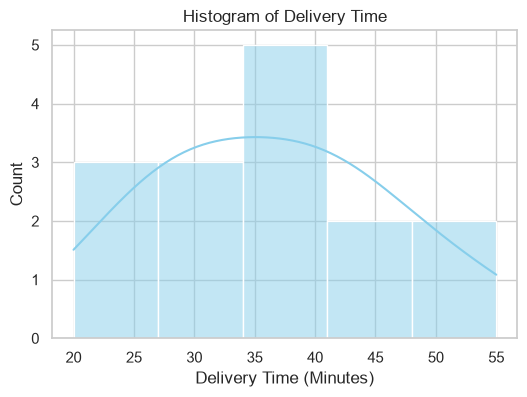

In [7]:
plt.figure(figsize=(6,4));sns.histplot(df['Delivery_Time_Minutes'],kde=True,color='skyblue');plt.title('Histogram of Delivery Time');plt.xlabel('Delivery Time (Minutes)');plt.show()

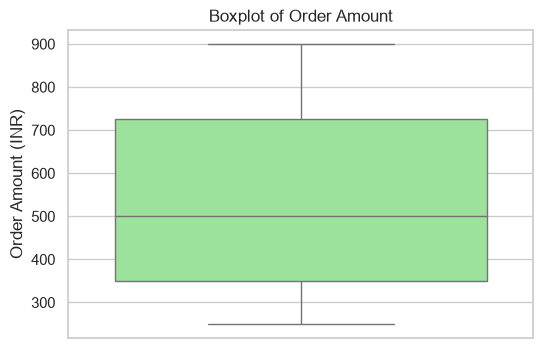

In [8]:
plt.figure(figsize=(6,4));sns.boxplot(y=df['Order_Amount'],color='lightgreen');plt.title('Boxplot of Order Amount');plt.ylabel('Order Amount (INR)');plt.show()

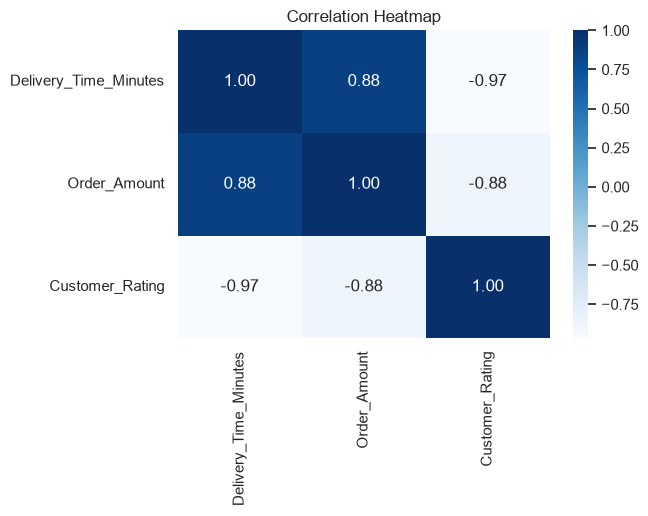

In [9]:
plt.figure(figsize=(6,4));sns.heatmap(corr_matrix,annot=True,cmap='Blues',fmt='.2f');plt.title('Correlation Heatmap');plt.show()

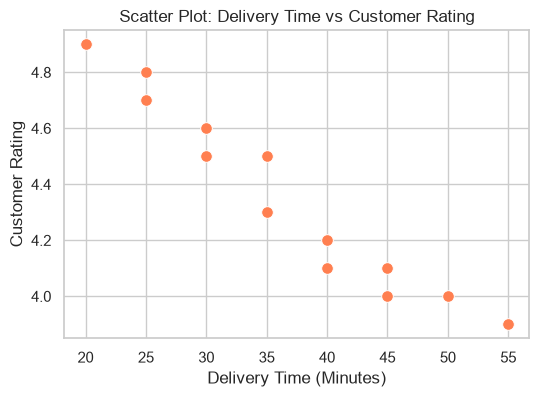

In [10]:
plt.figure(figsize=(6,4));sns.scatterplot(data=df,x='Delivery_Time_Minutes',y='Customer_Rating',color='coral',s=70);plt.title('Scatter Plot: Delivery Time vs Customer Rating');plt.xlabel('Delivery Time (Minutes)');plt.ylabel('Customer Rating');plt.show()